# 02. Exploratory Data Analysis (EDA) - Oceanic Niño Index (ONI)

Notebook ini menganalisis dataset **Oceanic Niño Index (ONI)** resmi dari NOAA Climate Prediction Center (CPC).
ONI merupakan indeks operasional standar utama NOAA untuk memantau, mengidentifikasi, dan mengklasifikasikan fenomena **El Niño** dan **La Niña** (ENSO - *El Niño-Southern Oscillation*).

### Tujuan Analisis:
1. Memverifikasi struktur, kelengkapan, dan integritas data historis ONI (1950–sekarang).
2. Memvisualisasikan evolusi deret waktu anomali suhu muka laut (SST) di wilayah Niño 3.4.
3. Mengklasifikasikan fase ENSO (El Niño, Neutral, La Niña) dan tingkat keparahannya (*Weak, Moderate, Strong, Very Strong*) berdasarkan ambang batas resmi NOAA (±0.5°C selama minimal 5 musim berturut-turut).
4. Menganalisis siklus musiman (*phase locking*) ENSO dan tren pemanasan global jangka panjang pada nilai SST total.
5. Mengevaluasi autokorelasi (ACF & PACF) untuk memahami skala waktu memori dan kuasi-periodisitas siklus ENSO.
6. Menganalisis secara mendalam periode proyek (2015–2025) sebagai acuan pemodelan prediktif regional.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# Konfigurasi Path fleksibel (mendukung eksekusi dari root maupun subfolder notebook)
DATA_DIR = Path("dataset/data_oni") if Path("dataset/data_oni").exists() else Path("../dataset/data_oni")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "oni.csv"
print(f"Dataset path: {CSV_PATH.resolve()}")
print(f"Output figures dir: {OUTPUT_DIR.resolve()}")

Dataset path: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_oni\oni.csv
Output figures dir: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures


## 2. Memuat Data dan Pra-pemrosesan Temporal

Dataset ONI menyajikan nilai SST rata-rata 3-bulan (*3-month running mean*) pada wilayah Niño 3.4 (5°N–5°S, 120°–170°W) dalam format kolom:
- `SEAS`: Musim tumpang-tindih (DJF, JFM, FMA, MAM, AMJ, MJJ, JJA, JAS, ASO, SON, OND, NDJ)
- `YR`: Tahun observasi (1950 – sekarang)
- `TOTAL`: Suhu permukaan laut absolut (°C)
- `ANOM`: Anomali suhu permukaan laut (°C) relatif terhadap base period klimatologi 30 tahun terkini.

Kita mengonversi triplet musim menjadi representasi datetime kontinu (bulan tengah musim) untuk analisis deret waktu.

In [2]:
# Memuat dataset
df_oni = pd.read_csv(CSV_PATH)

# Pemetaan musim 3-bulanan ke nomor bulan tengah
season_to_month = {
    'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4,
    'AMJ': 5, 'MJJ': 6, 'JJA': 7, 'JAS': 8,
    'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12
}

df_oni['Month'] = df_oni['SEAS'].map(season_to_month)
df_oni['Date'] = pd.to_datetime(df_oni['YR'].astype(str) + '-' + df_oni['Month'].astype(str) + '-01')
df_oni = df_oni.sort_values('Date').reset_index(drop=True)

# Tampilkan ringkasan info dan missing values
print("=== INFORMASI DATASET ONI ===")
print(df_oni.info())
print("\nPengecekan Missing Value:")
print(df_oni.isnull().sum())
print(f"\nRentang Waktu: {df_oni['Date'].min().strftime('%B %Y')} s.d. {df_oni['Date'].max().strftime('%B %Y')} ({len(df_oni)} observasi)")
df_oni.head(10)

=== INFORMASI DATASET ONI ===
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   SEAS    920 non-null    str           
 1   YR      920 non-null    int64         
 2   TOTAL   920 non-null    float64       
 3   ANOM    920 non-null    float64       
 4   Month   920 non-null    int64         
 5   Date    920 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(2), int64(2), str(1)
memory usage: 45.9 KB
None

Pengecekan Missing Value:
SEAS     0
YR       0
TOTAL    0
ANOM     0
Month    0
Date     0
dtype: int64

Rentang Waktu: January 1950 s.d. August 2026 (920 observasi)


,SEAS,YR,TOTAL,ANOM,Month,Date
0,DJF,1950,25.01,-1.32,1,1950-01-01
1,JFM,1950,25.36,-1.20,2,1950-02-01
2,FMA,1950,25.88,-1.12,3,1950-03-01
3,MAM,1950,26.24,-1.08,4,1950-04-01
4,AMJ,1950,26.35,-1.10,5,1950-05-01
5,MJJ,1950,26.32,-0.90,6,1950-06-01
6,JJA,1950,26.24,-0.62,7,1950-07-01
7,JAS,1950,25.94,-0.57,8,1950-08-01
8,ASO,1950,25.76,-0.56,9,1950-09-01
9,SON,1950,25.60,-0.62,10,1950-10-01


## 3. Visualisasi Historis Deret Waktu Anomali ONI (1950–2026)

Plot deret waktu berikut menampilkan fluktuasi anomali ONI dari tahun 1950 hingga data terkini.
- Garis putus-putus merah (+0.5°C) menandakan ambang batas fase hangat (**El Niño**).
- Garis putus-putus biru (-0.5°C) menandakan ambang batas fase dingin (**La Niña**).
- Peristiwa *Super El Niño* (1982/83, 1997/98, 2015/16, dan 2023/24) ditandai secara khusus.

findfont: Failed to find font weight semibold, now using 700.


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\11_oni_timeseries_anomaly_1950_2026.png


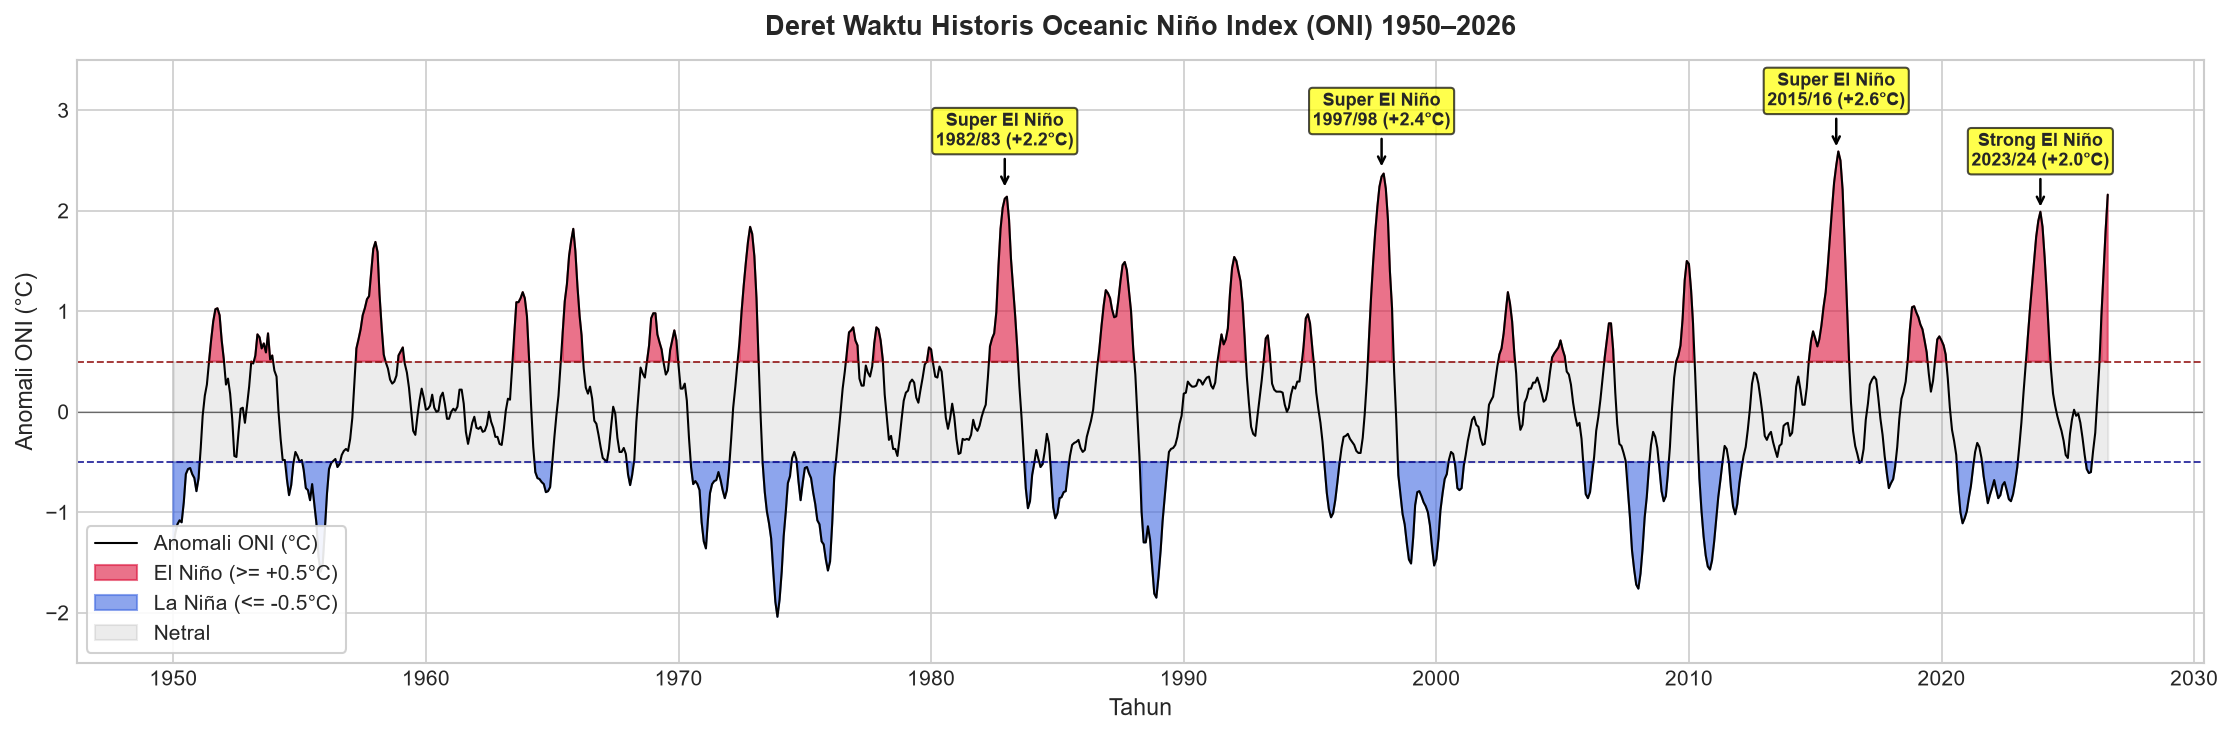

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))

# Plot kurva anomali
ax.plot(df_oni['Date'], df_oni['ANOM'], color='black', linewidth=1.0, label='Anomali ONI (°C)')

# Shading warna fase hangat dan dingin
ax.fill_between(df_oni['Date'], df_oni['ANOM'], 0.5, where=(df_oni['ANOM'] >= 0.5), color='crimson', alpha=0.6, label='El Niño (>= +0.5°C)')
ax.fill_between(df_oni['Date'], df_oni['ANOM'], -0.5, where=(df_oni['ANOM'] <= -0.5), color='royalblue', alpha=0.6, label='La Niña (<= -0.5°C)')
ax.fill_between(df_oni['Date'], -0.5, 0.5, color='gray', alpha=0.15, label='Netral')

# Garis ambang batas
ax.axhline(0.5, color='darkred', linestyle='--', linewidth=0.9, alpha=0.8)
ax.axhline(-0.5, color='darkblue', linestyle='--', linewidth=0.9, alpha=0.8)
ax.axhline(0.0, color='black', linestyle='-', linewidth=0.6, alpha=0.5)

# Anotasi Super El Niño
super_events = [
    ('1982-12-01', 2.2, 'Super El Niño\n1982/83 (+2.2°C)'),
    ('1997-11-01', 2.4, 'Super El Niño\n1997/98 (+2.4°C)'),
    ('2015-11-01', 2.6, 'Super El Niño\n2015/16 (+2.6°C)'),
    ('2023-12-01', 2.0, 'Strong El Niño\n2023/24 (+2.0°C)')
]

for date_str, y_pos, label_text in super_events:
    target_dt = pd.to_datetime(date_str)
    ax.annotate(label_text, xy=(target_dt, y_pos), xytext=(target_dt, y_pos + 0.45),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=8.5, ha='center', fontweight='semibold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))

ax.set_title("Deret Waktu Historis Oceanic Niño Index (ONI) 1950–2026", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Tahun", fontsize=11)
ax.set_ylabel("Anomali ONI (°C)", fontsize=11)
ax.set_ylim(-2.5, 3.5)
ax.legend(loc='lower left', frameon=True, framealpha=0.9)
plt.tight_layout()

fig_path_11 = OUTPUT_DIR / "11_oni_timeseries_anomaly_1950_2026.png"
plt.savefig(fig_path_11)
print(f"Gambar disimpan di: {fig_path_11.resolve()}")
plt.show()

## 4. Klasifikasi Fase ENSO & Distribusi Kategori Intensitas

Sesuai kriteria resmi NOAA CPC:
- Periode El Niño penuh terjadi ketika anomali ONI mencapai **+0.5°C atau lebih** selama **minimal 5 musim berturut-turut**.
- Periode La Niña penuh terjadi ketika anomali ONI mencapai **-0.5°C atau kurang** selama **minimal 5 musim berturut-turut**.
- Intensitas dikelompokkan menjadi:
  - **Weak**: Anomali 0.5 s.d. 0.9°C (atau -0.5 s.d. -0.9°C)
  - **Moderate**: Anomali 1.0 s.d. 1.4°C (atau -1.0 s.d. -1.4°C)
  - **Strong**: Anomali 1.5 s.d. 1.9°C (atau -1.5 s.d. -1.9°C)
  - **Very Strong**: Anomali >= 2.0°C (atau <= -2.0°C)

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_12380\2509329458.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=intensity_counts[order_intensity].values, y=order_intensity, ax=axes[1], palette=bar_colors)


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\12_oni_enso_category_distribution.png


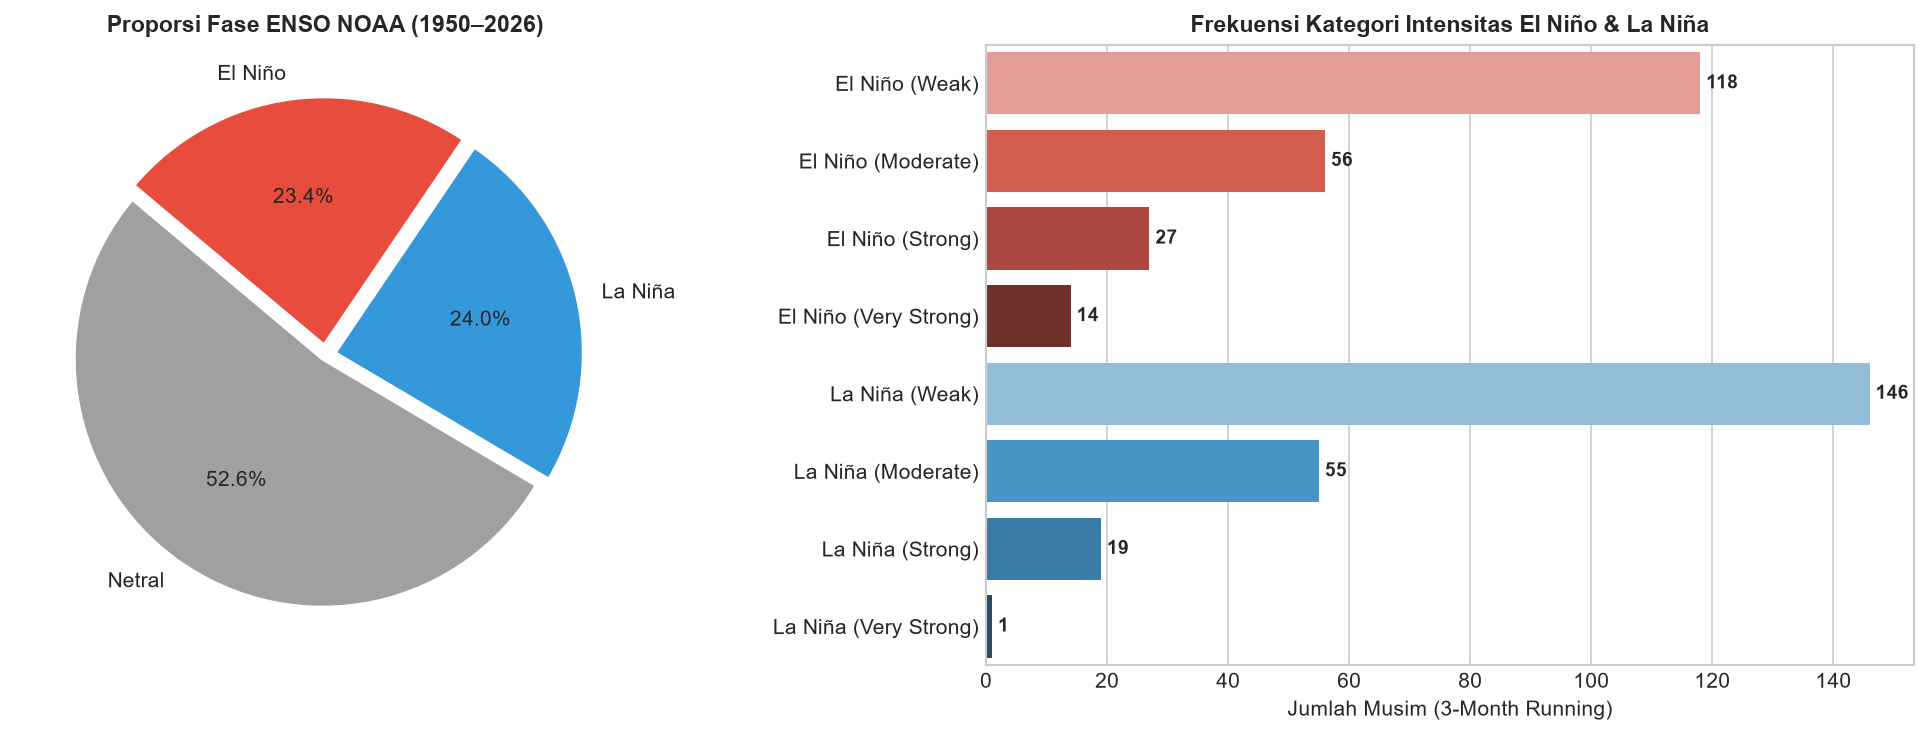

In [4]:
# Fungsi pelabelan episode NOAA (>= 5 consecutive seasons)
def label_noaa_episodes(anom_series, threshold=0.5, min_consecutive=5):
    # El Nino
    warm_mask = anom_series >= threshold
    warm_blocks = (warm_mask != warm_mask.shift()).cumsum()
    warm_counts = warm_mask.groupby(warm_blocks).transform('count')
    is_elnino = warm_mask & (warm_counts >= min_consecutive)
    
    # La Nina
    cold_mask = anom_series <= -threshold
    cold_blocks = (cold_mask != cold_mask.shift()).cumsum()
    cold_counts = cold_mask.groupby(cold_blocks).transform('count')
    is_lanina = cold_mask & (cold_counts >= min_consecutive)
    
    status = np.where(is_elnino, 'El Niño', np.where(is_lanina, 'La Niña', 'Netral'))
    return status

df_oni['ENSO_Phase'] = label_noaa_episodes(df_oni['ANOM'])

# Pelabelan Intensitas Detil
def classify_intensity(row):
    phase = row['ENSO_Phase']
    anom = abs(row['ANOM'])
    if phase == 'Netral':
        return 'Netral'
    elif anom >= 2.0:
        return f'{phase} (Very Strong)'
    elif anom >= 1.5:
        return f'{phase} (Strong)'
    elif anom >= 1.0:
        return f'{phase} (Moderate)'
    else:
        return f'{phase} (Weak)'

df_oni['Intensity_Class'] = df_oni.apply(classify_intensity, axis=1)

# Visualisasi Distribusi Fase dan Intensitas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Pie chart distribusi fase ENSO
phase_counts = df_oni['ENSO_Phase'].value_counts()
colors = {'Netral': '#a0a0a0', 'El Niño': '#e74c3c', 'La Niña': '#3498db'}
axes[0].pie(phase_counts, labels=phase_counts.index, autopct='%1.1f%%',
            startangle=140, colors=[colors[k] for k in phase_counts.index],
            explode=(0.02, 0.04, 0.04), wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title("Proporsi Fase ENSO NOAA (1950–2026)", fontsize=11, fontweight='bold')

# Plot 2: Bar chart kategori intensitas
intensity_counts = df_oni['Intensity_Class'].value_counts().drop('Netral', errors='ignore')
order_intensity = [
    'El Niño (Weak)', 'El Niño (Moderate)', 'El Niño (Strong)', 'El Niño (Very Strong)',
    'La Niña (Weak)', 'La Niña (Moderate)', 'La Niña (Strong)', 'La Niña (Very Strong)'
]
order_intensity = [o for o in order_intensity if o in intensity_counts.index]
bar_colors = ['#f1948a', '#e74c3c', '#c0392b', '#78281f', '#85c1e9', '#3498db', '#2980b9', '#1b4f72'][:len(order_intensity)]

sns.barplot(x=intensity_counts[order_intensity].values, y=order_intensity, ax=axes[1], palette=bar_colors)
axes[1].set_title("Frekuensi Kategori Intensitas El Niño & La Niña", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Jumlah Musim (3-Month Running)")
for i, v in enumerate(intensity_counts[order_intensity].values):
    axes[1].text(v + 1, i, str(v), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
fig_path_12 = OUTPUT_DIR / "12_oni_enso_category_distribution.png"
plt.savefig(fig_path_12)
print(f"Gambar disimpan di: {fig_path_12.resolve()}")
plt.show()

## 5. Analisis Siklus Musiman Puncak ENSO (Seasonality & Phase Locking)

Fenomena ENSO memiliki karakteristik fisik penting berupa **Phase Locking** terhadap siklus musiman tahunan.
El Niño dan La Niña cenderung berkembang pada musim semi/panas belahan bumi utara (MAM/JJA), mencapai puncak intensitas maksimum pada akhir tahun atau awal tahun (NDJ/DJF), dan mulai meluruh pada akhir musim dingin (FMA).

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_12380\241273796.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_oni, x='SEAS', y='ANOM', order=seasons_order, ax=axes[0], palette='coolwarm')


findfont: Failed to find font weight semibold, now using 700.


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\13_oni_seasonality_phase_locking.png


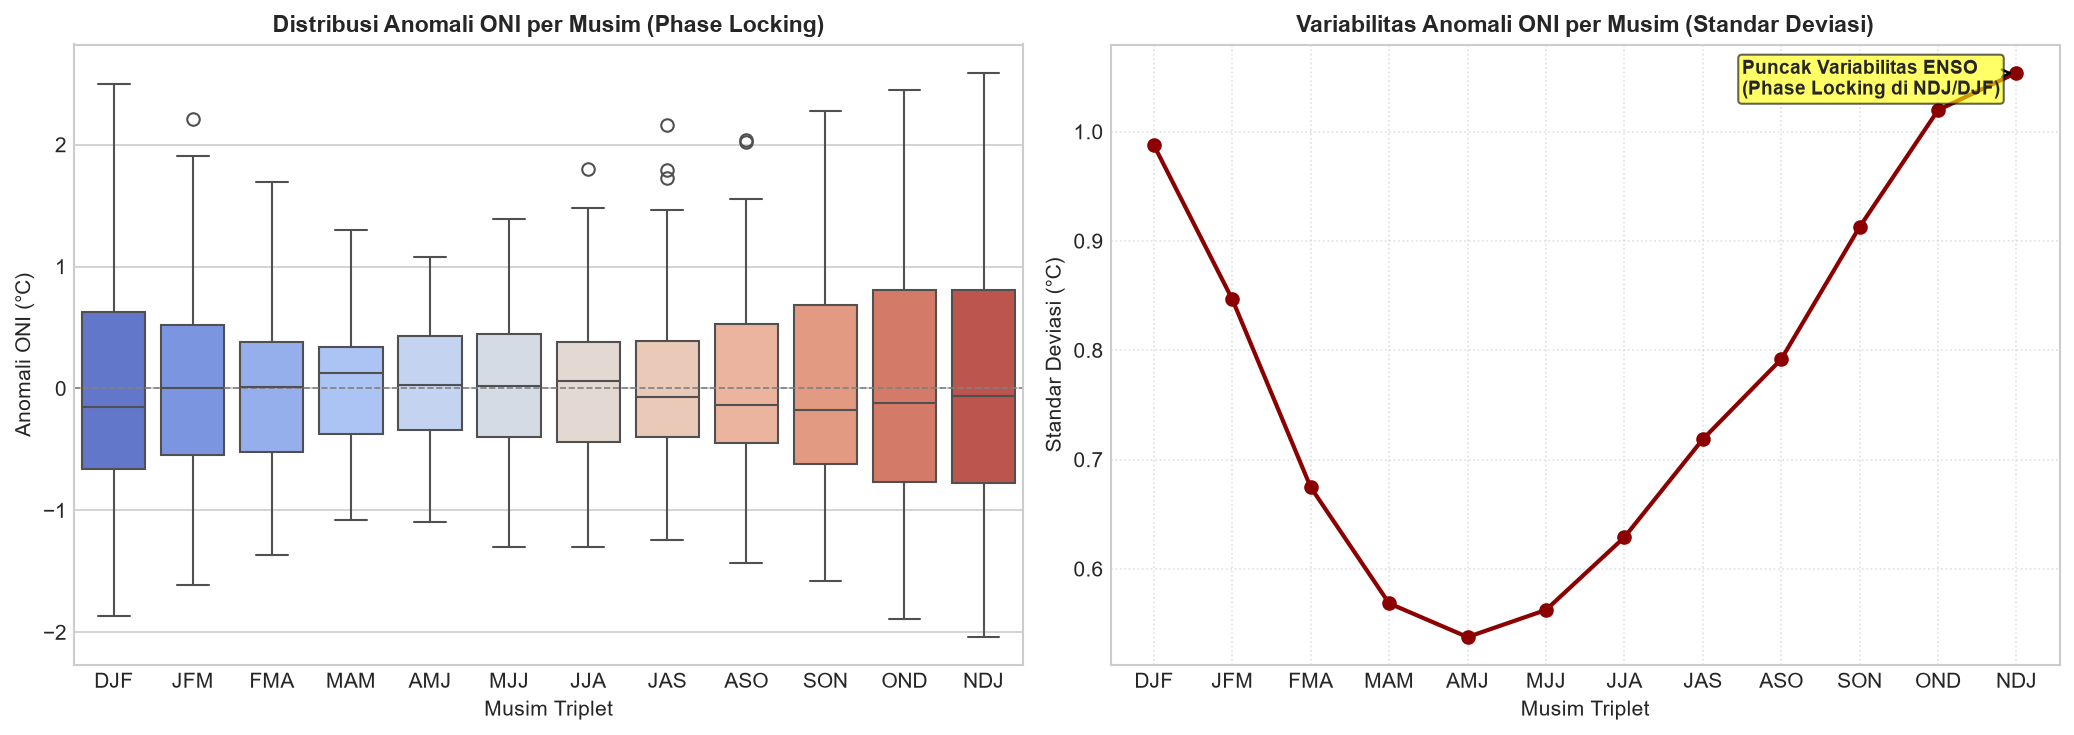

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Boxplot anomali ONI per triplet musim
seasons_order = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ']
sns.boxplot(data=df_oni, x='SEAS', y='ANOM', order=seasons_order, ax=axes[0], palette='coolwarm')
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_title("Distribusi Anomali ONI per Musim (Phase Locking)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Musim Triplet")
axes[0].set_ylabel("Anomali ONI (°C)")

# Plot 2: Standar deviasi (variansi) per musim membuktikan puncak variabilitas di NDJ/DJF
season_std = df_oni.groupby('SEAS')['ANOM'].std().reindex(seasons_order)
axes[1].plot(seasons_order, season_std.values, marker='o', color='darkred', linewidth=2.0)
axes[1].set_title("Variabilitas Anomali ONI per Musim (Standar Deviasi)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Musim Triplet")
axes[1].set_ylabel("Standar Deviasi (°C)")
axes[1].grid(True, linestyle=':', alpha=0.6)

# Highlight puncak variansi di NDJ dan DJF
axes[1].annotate("Puncak Variabilitas ENSO\n(Phase Locking di NDJ/DJF)",
                xy=(11, season_std.iloc[11]), xytext=(7.5, season_std.max() - 0.02),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=9, fontweight='semibold', bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.6))

plt.tight_layout()
fig_path_13 = OUTPUT_DIR / "13_oni_seasonality_phase_locking.png"
plt.savefig(fig_path_13)
print(f"Gambar disimpan di: {fig_path_13.resolve()}")
plt.show()

## 6. Analisis Dekadal & Tren Pemanasan Global pada SST Absolut

NOAA mendefinisikan ONI berdasarkan anomali terhadap base period 30 tahun yang diperbarui secara berkala (*centered 30-year base periods*).
Mengapa hal ini dilakukan? Karena suhu absolut rata-rata di wilayah Pasifik tropis terus meningkat akibat pemanasan global antropogenik.
Di bawah ini kita menganalisis tren kenaikan suhu rata-rata absolut per dekade.

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_12380\137241722.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=decade_stats, x='Decade_Label', y='mean', ax=axes[0], palette='Blues_d')


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\14_oni_sst_warming_trend_by_decade.png


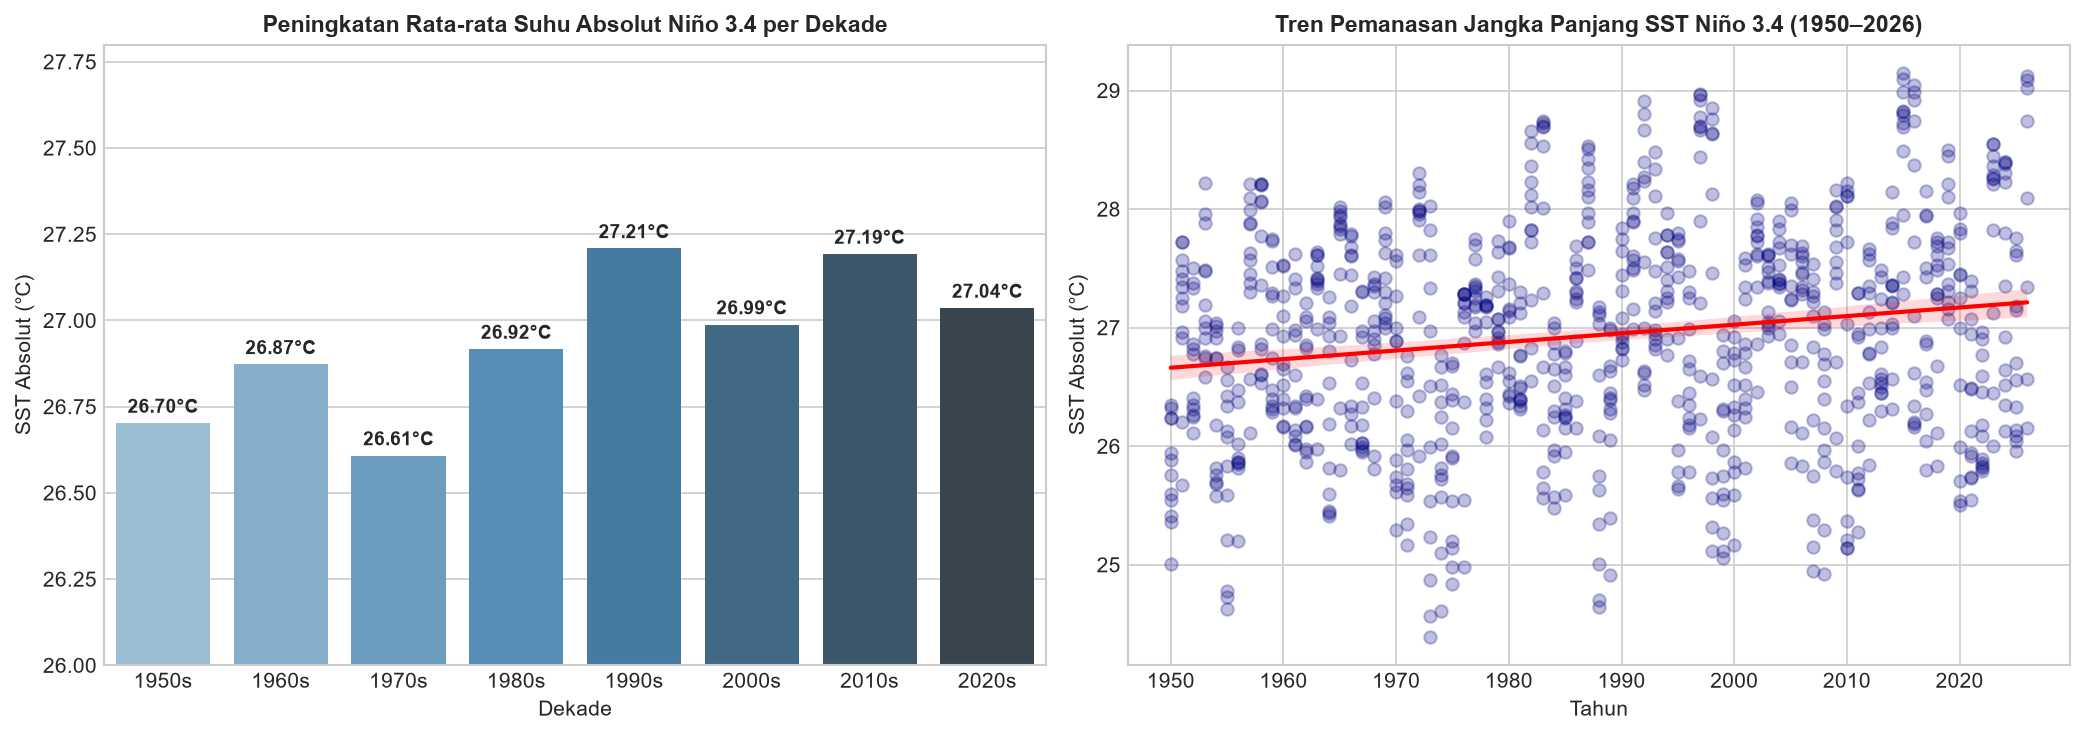

In [6]:
# Menghitung dekade
df_oni['Decade'] = (df_oni['YR'] // 10) * 10
df_oni['Decade_Label'] = df_oni['Decade'].astype(str) + "s"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Kenaikan SST Absolut Rata-rata per Dekade
decade_stats = df_oni.groupby('Decade_Label')['TOTAL'].agg(['mean', 'std']).reset_index()
sns.barplot(data=decade_stats, x='Decade_Label', y='mean', ax=axes[0], palette='Blues_d')
axes[0].set_ylim(26.0, 27.8)
axes[0].set_title("Peningkatan Rata-rata Suhu Absolut Niño 3.4 per Dekade", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Dekade")
axes[0].set_ylabel("SST Absolut (°C)")
for i, v in enumerate(decade_stats['mean']):
    axes[0].text(i, v + 0.03, f"{v:.2f}°C", ha='center', fontsize=9, fontweight='bold')

# Plot 2: Tren Waktu Deret SST Absolut dengan Regresi Linier
sns.regplot(data=df_oni, x='YR', y='TOTAL', ax=axes[1], scatter_kws={'alpha': 0.25, 'color': 'navy'}, line_kws={'color': 'red', 'linewidth': 2})
axes[1].set_title("Tren Pemanasan Jangka Panjang SST Niño 3.4 (1950–2026)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("SST Absolut (°C)")

plt.tight_layout()
fig_path_14 = OUTPUT_DIR / "14_oni_sst_warming_trend_by_decade.png"
plt.savefig(fig_path_14)
print(f"Gambar disimpan di: {fig_path_14.resolve()}")
plt.show()

## 7. Analisis Autokorelasi (ACF & PACF) dan Skala Kuasi-Periodik

ENSO dikenal memiliki sifat kuasi-periodik dengan siklus berulang antara **2 hingga 7 tahun** (24 hingga 84 bulan).
Analisis fungsi autokorelasi (ACF) dan autokorelasi parsial (PACF) memberikan wawasan krusial mengenai struktur lag autoregresif untuk penentuan *feature engineering* pada model deret waktu / machine learning.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\15_oni_acf_pacf_periodicity.png


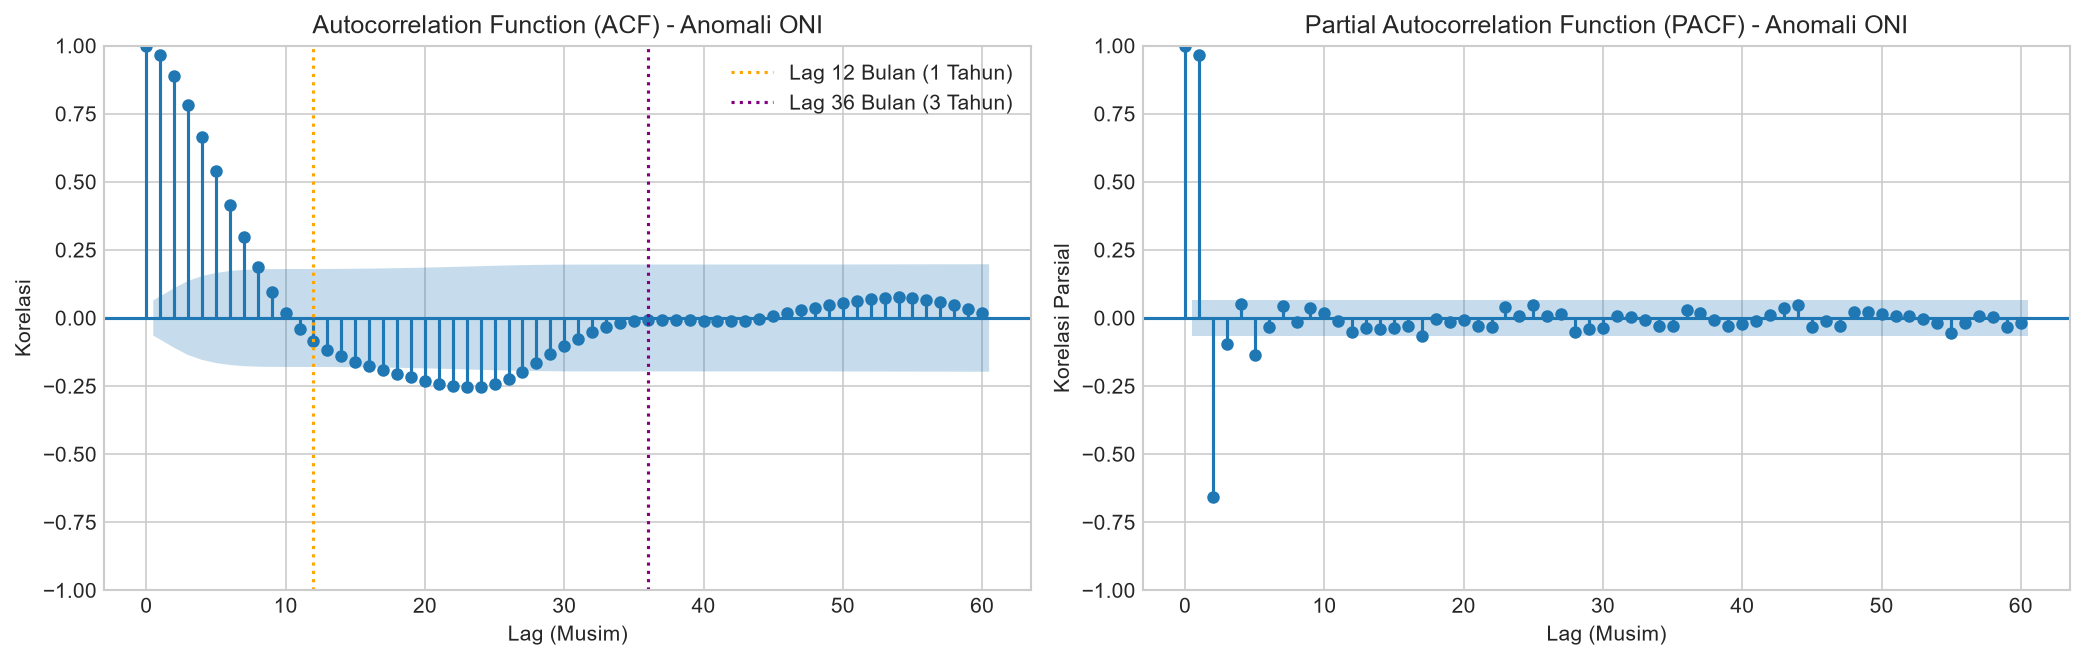

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(df_oni['ANOM'], lags=60, ax=axes[0], title="Autocorrelation Function (ACF) - Anomali ONI")
plot_pacf(df_oni['ANOM'], lags=60, ax=axes[1], title="Partial Autocorrelation Function (PACF) - Anomali ONI", method='ywm')

axes[0].set_xlabel("Lag (Musim)")
axes[0].set_ylabel("Korelasi")
axes[1].set_xlabel("Lag (Musim)")
axes[1].set_ylabel("Korelasi Parsial")

# Anotasi memori lag
axes[0].axvline(12, color='orange', linestyle=':', label='Lag 12 Bulan (1 Tahun)')
axes[0].axvline(36, color='purple', linestyle=':', label='Lag 36 Bulan (3 Tahun)')
axes[0].legend(loc='upper right')

plt.tight_layout()
fig_path_15 = OUTPUT_DIR / "15_oni_acf_pacf_periodicity.png"
plt.savefig(fig_path_15)
print(f"Gambar disimpan di: {fig_path_15.resolve()}")
plt.show()

## 8. Fokus Periode Proyek (2015–2025): Timeline Kejadian Terkini

Dataset utama citra dan SST regional dalam proyek penelitian ini mencakup rentang waktu **2015 hingga 2025**.
Bagian ini menyajikan rekonstruksi detil kejadian iklim utama pada rentang 11 tahun tersebut:
1. **Super El Niño 2015/2016** (anomali puncak mencapai +2.6°C).
2. **Fase Netral / La Niña Lemah 2016–2019**.
3. **Triple-Dip La Niña 2020–2023** (tiga tahun beruntun fase dingin yang intens).
4. **Strong El Niño 2023/2024** (kembalinya anomali hangat kuat di atas +2.0°C).

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\16_oni_focus_period_2015_2025.png


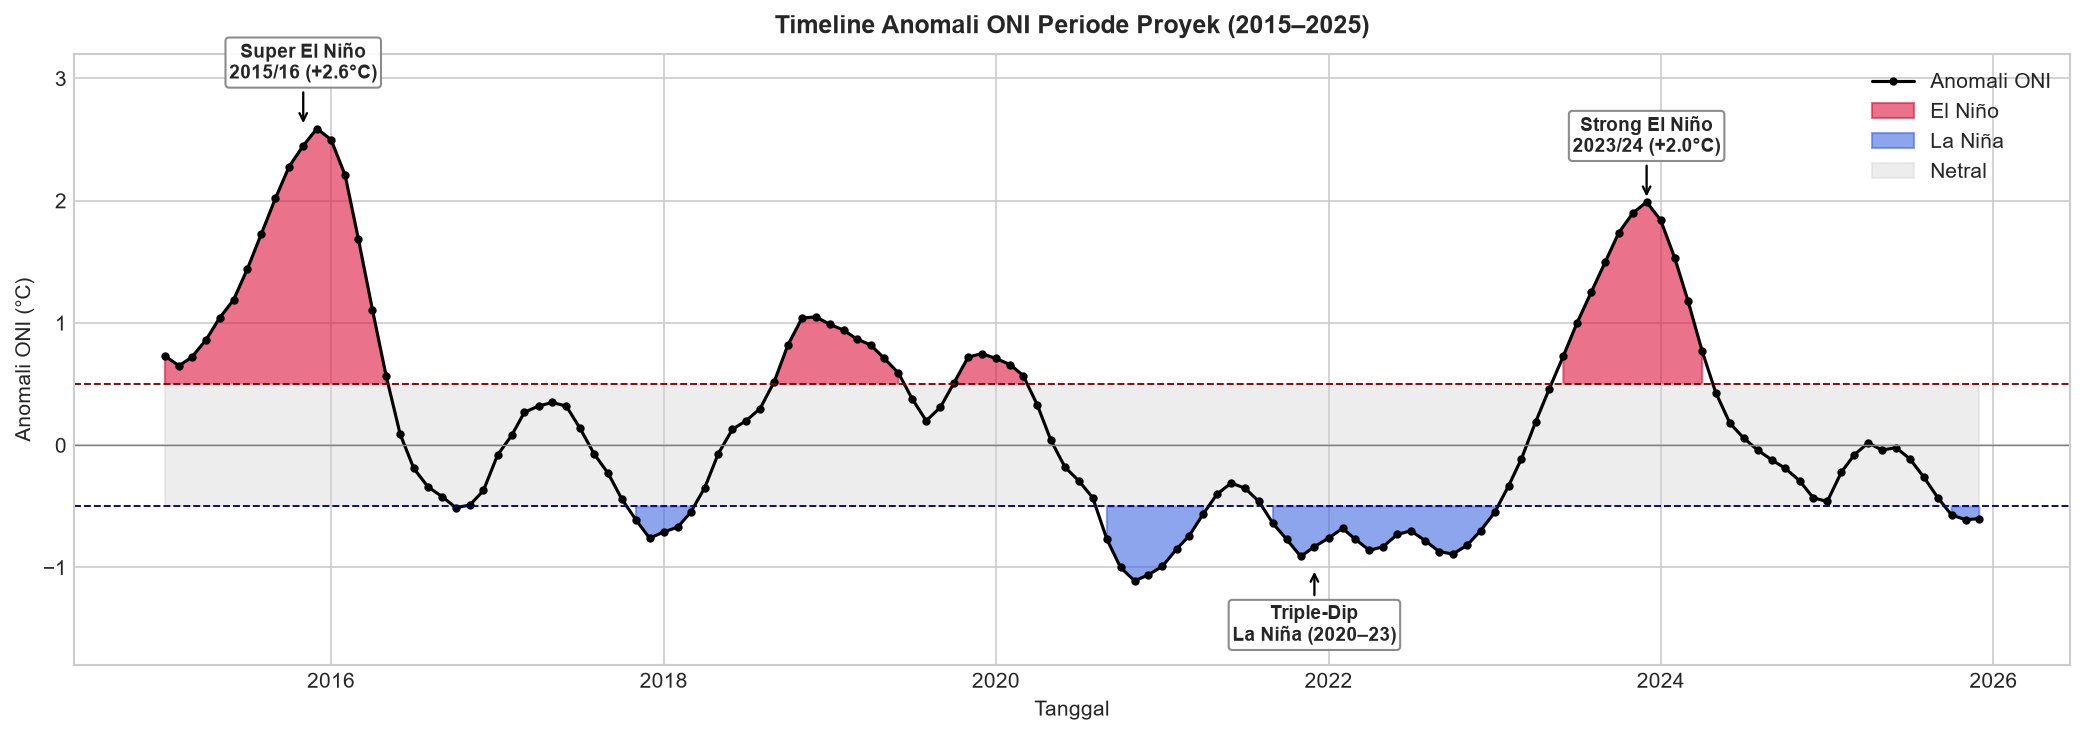

In [8]:
df_focus = df_oni[(df_oni['Date'] >= '2015-01-01') & (df_oni['Date'] <= '2025-12-31')].copy()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_focus['Date'], df_focus['ANOM'], color='black', linewidth=1.5, marker='o', markersize=3, label='Anomali ONI')

ax.fill_between(df_focus['Date'], df_focus['ANOM'], 0.5, where=(df_focus['ANOM'] >= 0.5), color='crimson', alpha=0.6, label='El Niño')
ax.fill_between(df_focus['Date'], df_focus['ANOM'], -0.5, where=(df_focus['ANOM'] <= -0.5), color='royalblue', alpha=0.6, label='La Niña')
ax.fill_between(df_focus['Date'], -0.5, 0.5, color='lightgray', alpha=0.4, label='Netral')

ax.axhline(0.5, color='darkred', linestyle='--', linewidth=0.9)
ax.axhline(-0.5, color='darkblue', linestyle='--', linewidth=0.9)
ax.axhline(0.0, color='gray', linestyle='-', linewidth=0.7)

# Anotasi kejadian spesifik
events_focus = [
    ('2015-11-01', 2.6, 'Super El Niño\n2015/16 (+2.6°C)'),
    ('2021-12-01', -1.0, 'Triple-Dip\nLa Niña (2020–23)'),
    ('2023-12-01', 2.0, 'Strong El Niño\n2023/24 (+2.0°C)')
]

for date_str, y_pos, label_text in events_focus:
    target_dt = pd.to_datetime(date_str)
    offset = 0.4 if y_pos > 0 else -0.6
    ax.annotate(label_text, xy=(target_dt, y_pos), xytext=(target_dt, y_pos + offset),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.1),
                fontsize=9, ha='center', fontweight='semibold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='gray', alpha=0.9))

ax.set_title("Timeline Anomali ONI Periode Proyek (2015–2025)", fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel("Tanggal", fontsize=10)
ax.set_ylabel("Anomali ONI (°C)", fontsize=10)
ax.set_ylim(-1.8, 3.2)
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()

fig_path_16 = OUTPUT_DIR / "16_oni_focus_period_2015_2025.png"
plt.savefig(fig_path_16)
print(f"Gambar disimpan di: {fig_path_16.resolve()}")
plt.show()

## 9. Kesimpulan & Relevansi terhadap Pemodelan

1. **Integritas Data**: Dataset ONI memiliki kualitas tinggi tanpa missing values dari 1950 hingga 2026 (920 musim observasi kontinu).
2. **Karakteristik Siklus**: Variabilitas ENSO terkonsentrasi pada kuasi-periodisitas 2–7 tahun dengan efek *phase locking* musiman yang sangat nyata pada akhir tahun (NDJ/DJF).
3. **Pemanasan Latar Belakang**: Terdapat tren pemanasan jangka panjang yang konsisten pada suhu rata-rata absolut Niño 3.4 (~0.5°C lebih hangat dalam 7 dekade terakhir), menegaskan pentingnya menggunakan anomali (atau Relative ONI) daripada suhu absolut untuk pemodelan klasifikasi iklim.
4. **Relevansi Fitur**: Autokorelasi ONI tetap signifikan hingga lag 12–18 bulan, menjadikannya fitur prediktor deret waktu yang sangat bernilai untuk memprediksi suhu laut lokal dan potensi cuaca ekstrem di perairan Indonesia.